# E-Commerce Marketing Analytics
**Author:** Amal Shesnij

## Setup: load the 8 tables

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.float_format', '{:,.2f}'.format)
pd.set_option('display.max_columns', None)

customers = pd.read_csv('CUSTOMERS.csv')
sellers   = pd.read_csv('SELLERS.csv')
products  = pd.read_csv('PRODUCTS.csv')
orders    = pd.read_csv('ORDERS.csv')
items     = pd.read_csv('ORDER_ITEMS.csv')
payments  = pd.read_csv('ORDER_PAYMENTS.csv')
reviews   = pd.read_csv('ORDER_REVIEW_RATINGS.csv')
geo       = pd.read_csv('GEO_LOCATION.csv')

for name, df in [('customers', customers), ('sellers', sellers), ('products', products),
                 ('orders', orders), ('items', items), ('payments', payments),
                 ('reviews', reviews), ('geo', geo)]:
    print(f'{name:10} {df.shape}')

customers  (99441, 5)
sellers    (3095, 4)
products   (32951, 9)
orders     (99441, 8)
items      (112650, 7)
payments   (103886, 5)
reviews    (100000, 5)
geo        (19015, 5)


### Checking the grain of each table

In [2]:
print('Orders                 :', orders['order_id'].nunique())
print('customer_id (unique)   :', customers['customer_id'].nunique())
print('customer_unique_id     :', customers['customer_unique_id'].nunique())
print('Orders with >1 item    :', (items.groupby('order_id').size() > 1).sum())
print('Orders with >1 payment :', (payments.groupby('order_id').size() > 1).sum())

Orders                 : 99441
customer_id (unique)   : 99441
customer_unique_id     : 96096
Orders with >1 item    : 9803


Orders with >1 payment : 2961


### Missing values and order status

In [3]:
for name, df in [('customers', customers), ('sellers', sellers), ('products', products),
                 ('orders', orders), ('items', items), ('payments', payments),
                 ('reviews', reviews), ('geo', geo)]:
    missing = df.isnull().sum()
    missing = missing[missing > 0]
    print(f'--- {name} ---')
    print(missing if len(missing) > 0 else 'No missing values')
    print()

print(orders['order_status'].value_counts())

--- customers ---
No missing values

--- sellers ---
seller_city     57
seller_state    57
dtype: int64

--- products ---
product_category_name         623
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64



--- orders ---
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

--- items ---
No missing values

--- payments ---
No missing values

--- reviews ---
No missing values

--- geo ---
No missing values

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


### Data cleaning

In [4]:
# Fill missing categories so they still appear in category analysis
products['product_category_name'] = products['product_category_name'].fillna('Unknown')
sellers[['seller_city', 'seller_state']] = sellers[['seller_city', 'seller_state']].fillna('Unknown')

# Convert date columns from text to real dates
date_cols = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
             'order_delivered_customer_date', 'order_estimated_delivery_date']
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col])

# Keep only valid orders (exclude canceled and unavailable)
valid_orders = orders[~orders['order_status'].isin(['canceled', 'unavailable'])]

print('Valid orders:', len(valid_orders))
print('Date range  :', valid_orders['order_purchase_timestamp'].min(), 'to',
      valid_orders['order_purchase_timestamp'].max())

Valid orders: 98207
Date range  : 2016-09-04 21:15:00 to 2018-09-03 09:06:00


### Data notes
- customer_id is created per order; customer_unique_id identifies the real customer (96,096 people).
- One order can have several items (9,803 orders) and several payments (2,961), so aggregate before joining.
- 623 products have no category, filled as "Unknown".
- Missing delivery dates belong to orders that were never delivered, so they are left blank.
- Canceled and unavailable orders (1,234) are excluded from revenue; 98,207 valid orders remain.
- Valid orders run from Sep 2016 to Sep 2018; the first and last months are partial.

## Q1a. Headline metrics

In [5]:
# Keep only rows that belong to valid orders
valid_ids = valid_orders['order_id']
v_items = items[items['order_id'].isin(valid_ids)]
v_payments = payments[payments['order_id'].isin(valid_ids)]

# Attach the real customer ID to each valid order
v_orders = valid_orders.merge(customers, on='customer_id', how='left')

metrics = {
    'Total orders'            : len(valid_orders),
    'Total customers'         : v_orders['customer_unique_id'].nunique(),
    'Product revenue (price)' : v_items['price'].sum(),
    'Freight revenue'         : v_items['freight_value'].sum(),
    'Total payments received' : v_payments['payment_value'].sum(),
    'Total quantity (items)'  : len(v_items),
    'Total products'          : v_items['product_id'].nunique(),
    'Total categories'        : products.loc[products['product_id'].isin(v_items['product_id']),
                                             'product_category_name'].nunique(),
    'Total sellers'           : v_items['seller_id'].nunique(),
    'Total states'            : v_orders['customer_state'].nunique(),
    'Total cities'            : v_orders['customer_city'].nunique(),
    'Payment methods'         : v_payments['payment_type'].nunique(),
}

pd.Series(metrics).to_frame('Value')

,Value
Total orders,"98,207.00"
Total customers,"94,990.00"
Product revenue (price),"13,494,400.74"
Freight revenue,"2,241,126.29"
Total payments received,"15,739,137.01"
Total quantity (items),"112,101.00"
Total products,"32,729.00"
Total categories,72.00
Total sellers,"3,053.00"
Total states,20.00


## Q1b. New customers acquired per month

Peak month: 2017-11 - 7190 new customers


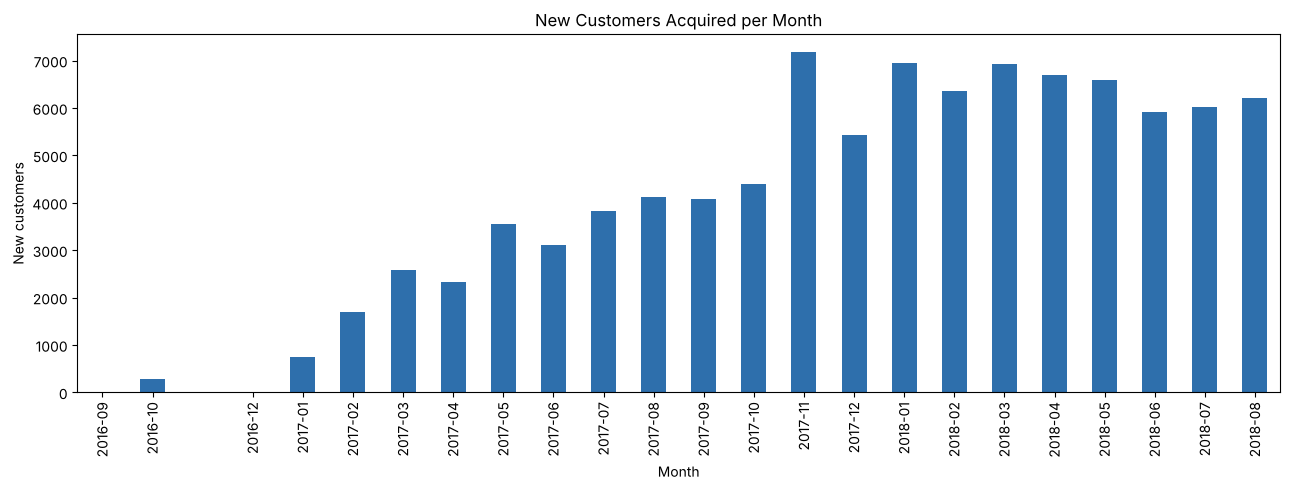

In [6]:
# Month of each order
v_orders['order_month'] = v_orders['order_purchase_timestamp'].dt.to_period('M')

# First purchase month of each real customer
first_month = v_orders.groupby('customer_unique_id')['order_month'].min()

new_customers = first_month.value_counts().sort_index()
print('Peak month:', new_customers.idxmax(), '-', new_customers.max(), 'new customers')

new_customers.plot(kind='bar', figsize=(13, 5), color='#2E6FAC')
plt.title('New Customers Acquired per Month')
plt.xlabel('Month'); plt.ylabel('New customers')
plt.tight_layout(); plt.show()

## Q1c. Customer retention

In [7]:
# Attach each customer's first month to every order
v_orders['first_month'] = v_orders['customer_unique_id'].map(first_month)

# Customers active each month, and those who had bought in an earlier month
active = v_orders.groupby('order_month')['customer_unique_id'].nunique()
returning = (v_orders[v_orders['order_month'] > v_orders['first_month']]
             .groupby('order_month')['customer_unique_id'].nunique())

retention = pd.DataFrame({'Active': active, 'Returning': returning}).fillna(0)
retention['Returning %'] = (retention['Returning'] / retention['Active'] * 100).round(2)

# Overall repeat rate
orders_per_customer = v_orders.groupby('customer_unique_id')['order_id'].nunique()
repeat = (orders_per_customer > 1).sum()
print(f'Customers with more than 1 order: {repeat} ({repeat / len(orders_per_customer):.2%})')

retention

Customers with more than 1 order: 2888 (3.04%)


,Active,Returning,Returning %
order_month,,,
2016-09,2,0.00,0.00
2016-10,290,0.00,0.00
2016-12,1,0.00,0.00
2017-01,753,1.00,0.13
2017-02,1693,3.00,0.18
2017-03,2577,6.00,0.23
2017-04,2345,20.00,0.85
2017-05,3569,28.00,0.78
2017-06,3142,40.00,1.27


## Q1d. Revenue from new vs existing customers

In [8]:
# Step 1: total payment per order (aggregate FIRST)
order_revenue = payments.groupby('order_id')['payment_value'].sum()

# Step 2: attach it to each valid order (one value per order, no duplication)
v_orders['revenue'] = v_orders['order_id'].map(order_revenue).fillna(0)

# Step 3: label each order New (customer's first month) or Existing (a later month)
v_orders['customer_type'] = (v_orders['order_month'] == v_orders['first_month']).map(
    {True: 'New', False: 'Existing'})

# Step 4: monthly revenue by type
rev_type = v_orders.pivot_table(index='order_month', columns='customer_type',
                                values='revenue', aggfunc='sum').fillna(0)
rev_type['Existing %'] = (rev_type['Existing'] / rev_type.sum(axis=1) * 100).round(2)

print('Total check:', round(v_orders['revenue'].sum(), 2))
rev_type

Total check: 15739137.01


customer_type,Existing,New,Existing %
order_month,,,
2016-09,0.00,136.23,0.00
2016-10,0.00,"51,657.53",0.00
2016-12,0.00,19.62,0.00
2017-01,19.62,"136,987.14",0.01
2017-02,170.83,"283,451.11",0.06
2017-03,650.82,"425,005.58",0.15
2017-04,"2,566.60","403,421.78",0.63
2017-05,"5,039.10","577,887.06",0.86
2017-06,"5,981.11","493,846.36",1.20


## Q1e. Sales trends by category, location and time

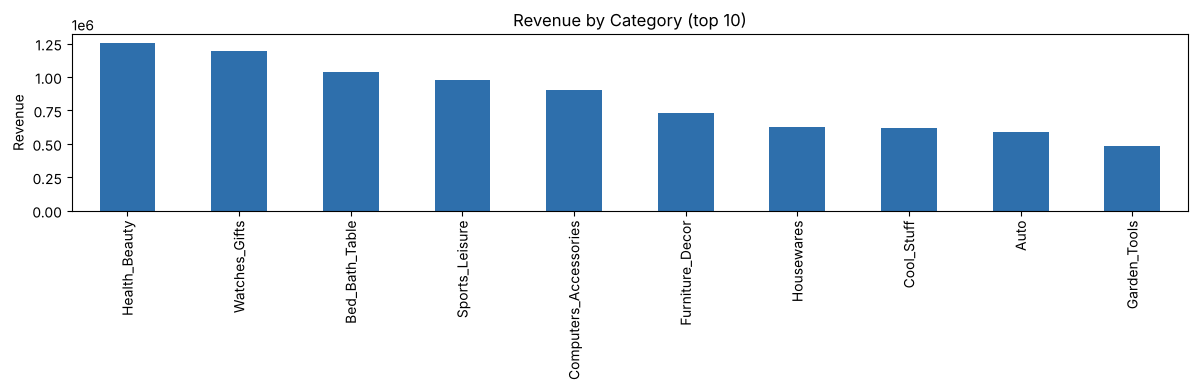

,Revenue,Quantity
product_category_name,,
Health_Beauty,"1,255,695.13",9634
Watches_Gifts,"1,198,185.21",5970
Bed_Bath_Table,"1,035,964.06",11097
Sports_Leisure,"979,740.92",8590
Computers_Accessories,"904,322.02",7781
Furniture_Decor,"727,465.05",8298
Housewares,"626,825.80",6915
Cool_Stuff,"620,770.49",3779
Auto,"586,585.73",4204


In [9]:
# One row per item sold, with its category, date and customer state
sales = (v_items
         .merge(products[['product_id', 'product_category_name']], on='product_id', how='left')
         .merge(v_orders[['order_id', 'order_purchase_timestamp', 'customer_state']],
                on='order_id', how='left'))

ts = sales['order_purchase_timestamp']
sales['month']   = ts.dt.to_period('M')
sales['weekday'] = ts.dt.day_name()
sales['hour']    = ts.dt.hour

def plot_sales(col, title, top=None, sort_by_value=True):
    summary = sales.groupby(col).agg(Revenue=('price', 'sum'), Quantity=('price', 'count'))
    if sort_by_value:
        summary = summary.sort_values('Revenue', ascending=False)
    if top:
        summary = summary.head(top)
    summary['Revenue'].plot(kind='bar', figsize=(12, 4), color='#2E6FAC')
    plt.title(f'Revenue by {title}'); plt.ylabel('Revenue'); plt.xlabel('')
    plt.tight_layout(); plt.show()
    return summary

plot_sales('product_category_name', 'Category (top 10)', top=10)

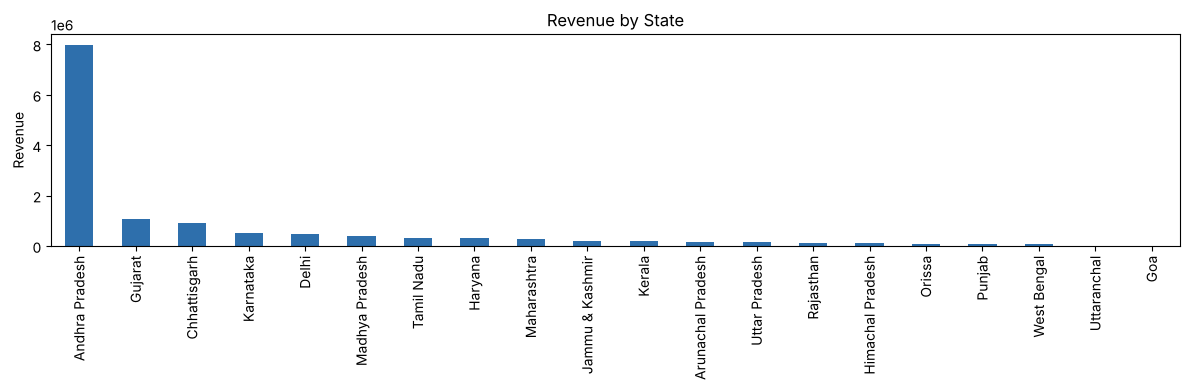

,Revenue,Quantity
customer_state,,
Andhra Pradesh,"7,997,900.13",68711
Gujarat,"1,053,146.09",8459
Chhattisgarh,"923,165.76",7076
Karnataka,"523,016.27",4322
Delhi,"488,827.40",3734
Madhya Pradesh,"411,313.17",3217
Tamil Nadu,"308,968.82",2349
Haryana,"302,778.98",2484
Maharashtra,"275,437.92",2241


In [10]:
plot_sales('customer_state', 'State')

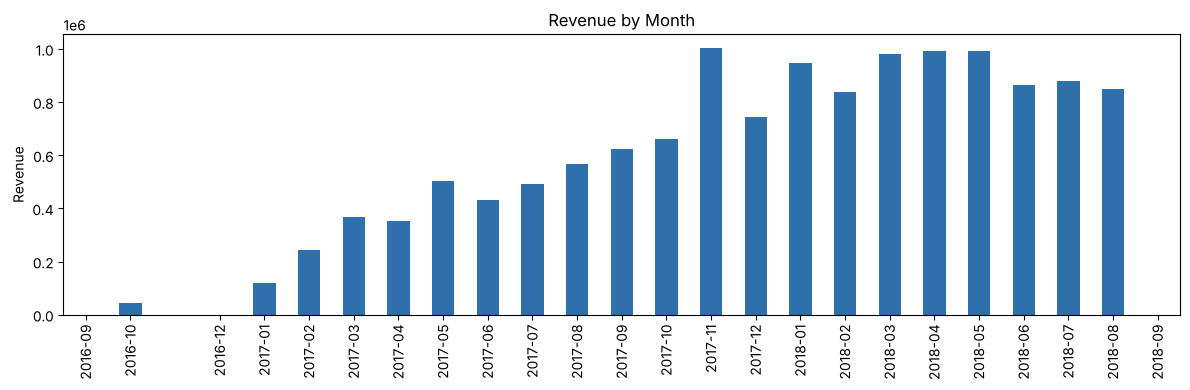

,Revenue,Quantity
month,,
2016-09,207.86,5
2016-10,"44,507.30",342
2016-12,10.90,1
2017-01,"120,098.27",953
2017-02,"244,959.35",1936
2017-03,"368,341.32",2975
2017-04,"353,842.98",2660
2017-05,"503,159.19",4106
2017-06,"429,916.61",3571


In [11]:
plot_sales('month', 'Month', sort_by_value=False)

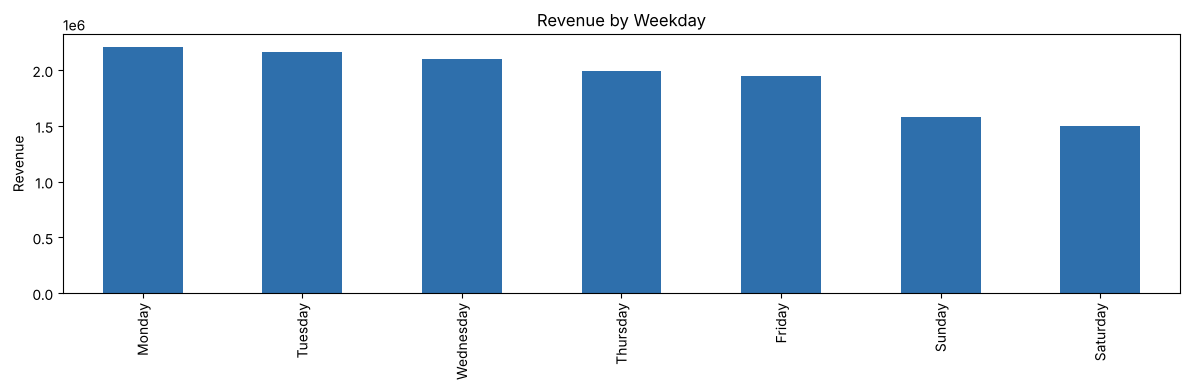

,Revenue,Quantity
weekday,,
Monday,"2,209,954.95",18288
Tuesday,"2,163,486.32",18147
Wednesday,"2,099,718.06",17514
Thursday,"1,996,006.74",16713
Friday,"1,951,765.20",15977
Sunday,"1,576,807.68",13348
Saturday,"1,496,661.79",12114


In [12]:
plot_sales('weekday', 'Weekday')

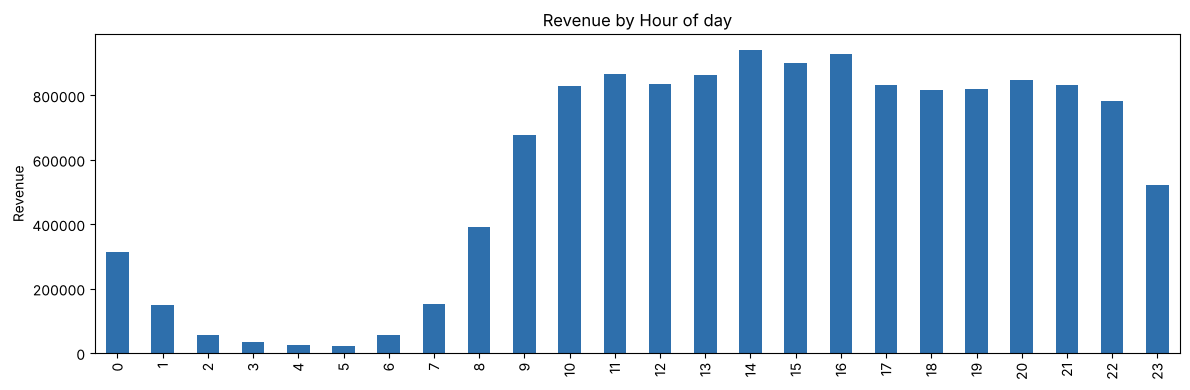

,Revenue,Quantity
hour,,
0,"313,415.57",2700
1,"149,642.53",1284
2,"54,754.52",582
3,"35,329.70",312
4,"24,281.59",244
5,"22,074.01",216
6,"56,409.30",549
7,"152,054.28",1367
8,"391,013.99",3370


In [13]:
plot_sales('hour', 'Hour of day', sort_by_value=False)

## Q1f. Popular products

In [14]:
def top_per_group(group_col, item_col):
    counts = (sales.groupby([group_col, item_col]).size()
                   .reset_index(name='Units')
                   .sort_values('Units', ascending=False))
    return counts.drop_duplicates(group_col).sort_values(group_col).reset_index(drop=True)

# Overall top 10 products
top_products = (sales.groupby(['product_id', 'product_category_name']).size()
                     .sort_values(ascending=False).head(10).reset_index(name='Units'))
top_products

,product_id,product_category_name,Units
0,aca2eb7d00ea1a7b8ebd4e68314663af,Furniture_Decor,527
1,99a4788cb24856965c36a24e339b6058,Bed_Bath_Table,487
2,422879e10f46682990de24d770e7f83d,Garden_Tools,484
3,389d119b48cf3043d311335e499d9c6b,Garden_Tools,391
4,368c6c730842d78016ad823897a372db,Garden_Tools,388
5,53759a2ecddad2bb87a079a1f1519f73,Garden_Tools,373
6,d1c427060a0f73f6b889a5c7c61f2ac4,Computers_Accessories,341
7,53b36df67ebb7c41585e8d54d6772e08,Watches_Gifts,323
8,154e7e31ebfa092203795c972e5804a6,Health_Beauty,281
9,3dd2a17168ec895c781a9191c1e95ad7,Computers_Accessories,274


### Most popular product by month, state, category and seller

In [15]:
top_per_group('month', 'product_id')

,month,product_id,Units
0,2016-09,5a6b04657a4c5ee34285d1e4619a96b4,3
1,2016-10,eba7488e1c67729f045ab43fac426f2e,9
2,2016-12,f5d8f4fbc70ca2a0038b9a0010ed5cb0,1
3,2017-01,37eb69aca8718e843d897aa7b82f462d,15
4,2017-02,a703f5ade6e4fae527357132230ea778,13
5,2017-03,7e0dc102074f8285580c9777f79c90cf,45
6,2017-04,99a4788cb24856965c36a24e339b6058,34
7,2017-05,99a4788cb24856965c36a24e339b6058,58
8,2017-06,42a2c92a0979a949ca4ea89ec5c7b934,73
9,2017-07,99a4788cb24856965c36a24e339b6058,60


In [16]:
top_per_group('customer_state', 'product_id')

,customer_state,product_id,Units
0,Andhra Pradesh,aca2eb7d00ea1a7b8ebd4e68314663af,345
1,Arunachal Pradesh,03e1c946c0ddfc58724ff262aef08dff,12
2,Chhattisgarh,368c6c730842d78016ad823897a372db,40
3,Delhi,53759a2ecddad2bb87a079a1f1519f73,22
4,Goa,2a5806f10d0f00e5ad032dd2e3c8806e,1
5,Gujarat,53759a2ecddad2bb87a079a1f1519f73,45
6,Haryana,2b4609f8948be18874494203496bc318,13
7,Himachal Pradesh,422879e10f46682990de24d770e7f83d,6
8,Jammu & Kashmir,89b190a046022486c635022524a974a8,15
9,Karnataka,422879e10f46682990de24d770e7f83d,24


In [17]:
top_per_group('product_category_name', 'product_id').sort_values('Units', ascending=False).head(10)

,product_category_name,product_id,Units
39,Furniture_Decor,aca2eb7d00ea1a7b8ebd4e68314663af,527
7,Bed_Bath_Table,99a4788cb24856965c36a24e339b6058,487
42,Garden_Tools,422879e10f46682990de24d770e7f83d,484
15,Computers_Accessories,d1c427060a0f73f6b889a5c7c61f2ac4,341
71,Watches_Gifts,53b36df67ebb7c41585e8d54d6772e08,323
43,Health_Beauty,154e7e31ebfa092203795c972e5804a6,281
70,Unknown,5a848e4ab52fd5445cdc07aab1c40e48,197
49,Housewares,42a2c92a0979a949ca4ea89ec5c7b934,183
47,Home_Confort,35afc973633aaeb6b877ff57b2793310,165
16,Consoles_Games,0aabfb375647d9738ad0f7b4ea3653b1,142


In [18]:
top_per_group('seller_id', 'product_id').sort_values('Units', ascending=False).head(10)

,seller_id,product_id,Units
1799,955fee9216a65b617aa5c0531780ce60,aca2eb7d00ea1a7b8ebd4e68314663af,527
366,1f50f920176fa81dab994f9023523100,422879e10f46682990de24d770e7f83d,484
873,4a3ca9315b744ce9f8e9374361493884,99a4788cb24856965c36a24e339b6058,481
1929,a1043bafd471dff536d0c462352beb48,d1c427060a0f73f6b889a5c7c61f2ac4,341
2451,cc419e0650a3c5ba77189a1882b7556a,154e7e31ebfa092203795c972e5804a6,281
2656,de722cd6dad950a92b7d4f82673f8833,3dd2a17168ec895c781a9191c1e95ad7,274
1198,634964b17796e64304cadf1ad3050fb7,a62e25e09e05e6faf31d90c6ec1aa3d1,225
1520,7d13fca15225358621be4086e1eb0964,53b36df67ebb7c41585e8d54d6772e08,214
2393,c826c40d7b19f62a09e2d7c5e7295ee2,5a848e4ab52fd5445cdc07aab1c40e48,197
2955,f7ba60f8c3f99e7ee4042fdef03b70c4,bb50f2e236e5eea0100680137654686c,195


## Q1g. Popular categories by state and month

In [19]:
top_per_group('customer_state', 'product_category_name')

,customer_state,product_category_name,Units
0,Andhra Pradesh,Bed_Bath_Table,7086
1,Arunachal Pradesh,Bed_Bath_Table,114
2,Chhattisgarh,Bed_Bath_Table,681
3,Delhi,Health_Beauty,327
4,Goa,Auto,1
5,Gujarat,Bed_Bath_Table,786
6,Haryana,Bed_Bath_Table,282
7,Himachal Pradesh,Bed_Bath_Table,83
8,Jammu & Kashmir,Bed_Bath_Table,160
9,Karnataka,Bed_Bath_Table,379


In [20]:
top_per_group('month', 'product_category_name')

,month,product_category_name,Units
0,2016-09,Health_Beauty,3
1,2016-10,Furniture_Decor,67
2,2016-12,Fashion_Bags_Accessories,1
3,2017-01,Furniture_Decor,182
4,2017-02,Furniture_Decor,265
5,2017-03,Furniture_Decor,327
6,2017-04,Bed_Bath_Table,274
7,2017-05,Bed_Bath_Table,368
8,2017-06,Bed_Bath_Table,382
9,2017-07,Bed_Bath_Table,578


## Q1h. Top 10 most expensive products

In [21]:
(sales.groupby(['product_id', 'product_category_name'])['price'].max()
      .sort_values(ascending=False).head(10).reset_index())

,product_id,product_category_name,price
0,489ae2aa008f021502940f251d4cce7f,Housewares,"6,735.00"
1,69c590f7ffc7bf8db97190b6cb6ed62e,Computers,"6,729.00"
2,1bdf5e6731585cf01aa8169c7028d6ad,Art,"6,499.00"
3,a6492cc69376c469ab6f61d8f44de961,Small_Appliances,"4,799.00"
4,c3ed642d592594bb648ff4a04cee2747,Small_Appliances,"4,690.00"
5,259037a6a41845e455183f89c5035f18,Computers,"4,590.00"
6,a1beef8f3992dbd4cd8726796aa69c53,Musical_Instruments,"4,399.87"
7,6cdf8fc1d741c76586d8b6b15e9eef30,Consoles_Games,"4,099.99"
8,dd113cb02b2af9c8e5787e8f1f0722f6,Sports_Leisure,"4,059.00"
9,6902c1962dd19d540807d0ab8fade5c6,Watches_Gifts,"3,999.90"


## Q2. Customer and seller segmentation

In [22]:
def segment(revenue, label):
    seg = pd.qcut(revenue.rank(method='first'), 4, labels=['Low', 'Medium', 'High', 'Top'])
    table = revenue.groupby(seg, observed=True).agg(['count', 'sum', 'min', 'max'])
    table.columns = [f'{label}s', 'Revenue', 'Min', 'Max']
    table['Revenue %'] = (table['Revenue'] / table['Revenue'].sum() * 100).round(2)
    return table

# Q2a: customers (total payments per real customer)
customer_revenue = v_orders.groupby('customer_unique_id')['revenue'].sum()
segment(customer_revenue, 'Customer')

,Customers,Revenue,Min,Max,Revenue %
revenue,,,,,
Low,23748,"1,036,493.85",0.00,63.10,6.59
Medium,23747,"1,987,268.64",63.10,107.90,12.63
High,23747,"3,354,630.88",107.90,182.94,21.31
Top,23748,"9,360,743.64",182.94,"13,664.08",59.47


### Q2b. Sellers

In [23]:
# Q2b: sellers (total product sales per seller)
seller_revenue = v_items.groupby('seller_id')['price'].sum()
segment(seller_revenue, 'Seller')

,Sellers,Revenue,Min,Max,Revenue %
price,,,,,
Low,764,"78,722.45",3.50,210.00,0.58
Medium,763,"359,357.16",210.20,825.00,2.66
High,763,"1,318,550.03",826.99,"3,353.48",9.77
Top,763,"11,737,771.10","3,381.73","229,237.63",86.98


## Q3. Cross-selling: products bought together

In [24]:
from itertools import combinations
from collections import Counter

# Distinct products per order, keeping only orders with 2+ different products
baskets = v_items.groupby('order_id')['product_id'].apply(lambda x: sorted(set(x)))
baskets = baskets[baskets.str.len() > 1]
print('Orders with 2+ different products:', len(baskets))

pairs = Counter(combo for basket in baskets for combo in combinations(basket, 2))
triples = Counter(combo for basket in baskets for combo in combinations(basket, 3))

top_pairs = pd.DataFrame(pairs.most_common(10), columns=['Product pair', 'Orders'])
top_pairs

Orders with 2+ different products: 3231


,Product pair,Orders
0,"(36f60d45225e60c7da4558b070ce4b60, e53e557d5a1...",34
1,"(35afc973633aaeb6b877ff57b2793310, 99a4788cb24...",29
2,"(4fcb3d9a5f4871e8362dfedbdb02b064, f4f67ccaece...",17
3,"(36f60d45225e60c7da4558b070ce4b60, 3f14d740544...",12
4,"(389d119b48cf3043d311335e499d9c6b, 422879e10f4...",11
5,"(389d119b48cf3043d311335e499d9c6b, 53759a2ecdd...",9
6,"(368c6c730842d78016ad823897a372db, 53759a2ecdd...",8
7,"(18486698933fbb64af6c0a255f7dd64c, dbb67791e40...",7
8,"(422879e10f46682990de24d770e7f83d, 53759a2ecdd...",7
9,"(060cb19345d90064d1015407193c233d, 98d61056e05...",6


In [25]:
pd.DataFrame(triples.most_common(10), columns=['Product trio', 'Orders'])

,Product trio,Orders
0,"(55bfa0307d7a46bed72c492259921231, b9900407a55...",3
1,"(1dc7685f4fdb9622d84ae2ec658d5bbf, b7d2c90f916...",2
2,"(4025ee582ef6b8c478af3b44cf89054b, c211ff3068f...",2
3,"(389d119b48cf3043d311335e499d9c6b, 422879e10f4...",2
4,"(368c6c730842d78016ad823897a372db, 389d119b48c...",2
5,"(1dc7685f4fdb9622d84ae2ec658d5bbf, a46875fb5b8...",2
6,"(07ffc018eaf23e086370dea42c74077b, 7eaf66aca1e...",2
7,"(23ab7bb9eac81e85ec43ed71064cf7ce, 94634469715...",2
8,"(946344697156947d846d27fe0d503033, ad0a798e794...",2
9,"(35afc973633aaeb6b877ff57b2793310, 99a4788cb24...",2


### Categories bought together

In [26]:
cat_baskets = (sales.groupby('order_id')['product_category_name']
                    .apply(lambda x: sorted(set(x))))
cat_baskets = cat_baskets[cat_baskets.str.len() > 1]
cat_pairs = Counter(c for b in cat_baskets for c in combinations(b, 2))
pd.DataFrame(cat_pairs.most_common(10), columns=['Category pair', 'Orders'])

,Category pair,Orders
0,"(Bed_Bath_Table, Furniture_Decor)",70
1,"(Bed_Bath_Table, Home_Confort)",43
2,"(Furniture_Decor, Housewares)",24
3,"(Bed_Bath_Table, Housewares)",20
4,"(Baby, Cool_Stuff)",20
5,"(Baby, Toys)",19
6,"(Furniture_Decor, Garden_Tools)",17
7,"(Baby, Bed_Bath_Table)",17
8,"(Housewares, Unknown)",14
9,"(Health_Beauty, Sports_Leisure)",14


## Q4. Payment behaviour

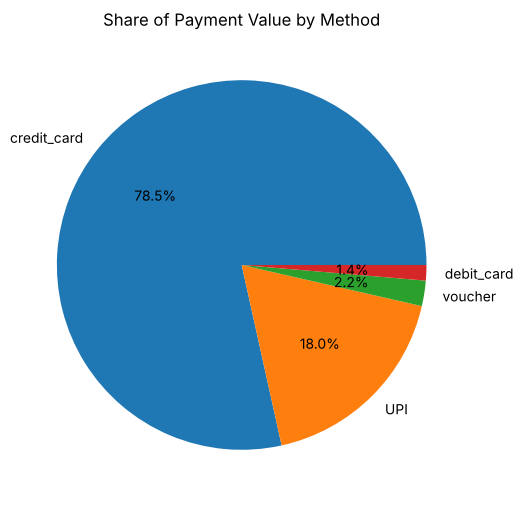

,Transactions,Customers,Total_value,Avg_value,Value %
payment_type,,,,,
credit_card,75905,73270,"12,350,042.56",162.70,78.47
UPI,19539,19056,"2,826,802.30",144.67,17.96
voucher,5613,3654,"349,874.40",62.33,2.22
debit_card,1516,1500,"212,417.75",140.12,1.35


In [27]:
# Attach the real customer to each valid payment
pay = v_payments.merge(v_orders[['order_id', 'customer_unique_id']], on='order_id', how='left')

pay_summary = pay.groupby('payment_type').agg(
    Transactions=('order_id', 'count'),
    Customers=('customer_unique_id', 'nunique'),
    Total_value=('payment_value', 'sum'),
    Avg_value=('payment_value', 'mean'))
pay_summary['Value %'] = (pay_summary['Total_value'] / pay_summary['Total_value'].sum() * 100).round(2)
pay_summary = pay_summary.sort_values('Total_value', ascending=False)

pay_summary['Value %'].plot(kind='pie', autopct='%1.1f%%', figsize=(6, 6), ylabel='')
plt.title('Share of Payment Value by Method'); plt.show()

pay_summary

In [28]:
cc = pay[pay['payment_type'] == 'credit_card']
print(f"Credit card payments in more than 1 instalment: {(cc['payment_installments'] > 1).mean():.1%}")
print('Average number of instalments:', round(cc['payment_installments'].mean(), 1))

Credit card payments in more than 1 instalment: 66.9%
Average number of instalments: 3.5


## Q5. Customer satisfaction

In [29]:
# One average score per order (a few orders have more than one review)
order_score = reviews.groupby('order_id')['review_score'].mean()

sales['score'] = sales['order_id'].map(order_score)
v_orders['score'] = v_orders['order_id'].map(order_score)

print('Average rating:', round(v_orders['score'].mean(), 2))
print((reviews['review_score'].value_counts(normalize=True).sort_index() * 100).round(1))

Average rating: 4.1
review_score
1   11.90
2    3.20
3    8.30
4   19.20
5   57.40
Name: proportion, dtype: float64


### Q5a. Ratings by category

In [30]:
cat_rating = sales.groupby('product_category_name')['score'].agg(['mean', 'count'])
cat_rating = cat_rating[cat_rating['count'] >= 30]   # ignore categories with too few reviews

print('Highest rated categories')
display(cat_rating.sort_values('mean', ascending=False).head(10).round(2))
print('Lowest rated categories')
display(cat_rating.sort_values('mean').head(10).round(2))

Highest rated categories


,mean,count
product_category_name,,
Books_General_Interest,4.48,546
Books_Imported,4.40,60
Costruction_Tools_Tools,4.36,103
Books_Technical,4.33,267
Food_Drink,4.32,276
Luggage_Accessories,4.32,1088
Small_Appliances_Home_Oven_And_Coffee,4.30,76
Fashion_Sport,4.23,30
Fashion_Shoes,4.23,260


Lowest rated categories


,mean,count
product_category_name,,
Diapers_And_Hygiene,3.32,38
Home_Comfort_2,3.37,30
Office_Furniture,3.48,1690
Fashion_Male_Clothing,3.64,131
Fixed_Telephony,3.70,261
Party_Supplies,3.77,43
Fashio_Female_Clothing,3.78,48
Furniture_Mattress_And_Upholstery,3.82,38
Audio,3.82,363


### Q5b. Ratings by product

In [31]:
prod_rating = sales.groupby(['product_id', 'product_category_name'])['score'].agg(['mean', 'count'])
prod_rating = prod_rating[prod_rating['count'] >= 20]

print('Highest rated products')
display(prod_rating.sort_values(['mean', 'count'], ascending=False).head(10).round(2))
print('Lowest rated products')
display(prod_rating.sort_values(['mean', 'count'], ascending=[True, False]).head(10).round(2))

Highest rated products


,,mean,count
product_id,product_category_name,,
3e4176d545618ed02f382a3057de32b4,Luggage_Accessories,4.96,24
e7f85e7f0203b7b95cc1b4c21b4b070c,Cool_Stuff,4.87,23
73326828aa5efe1ba096223de496f596,Food,4.83,54
574597aaf385996112490308e37399ce,Housewares,4.83,24
f7f59e6186e10983a061ac7bdb3494d6,Housewares,4.82,39
990d135e28e075648cb7d83198fdccf4,Baby,4.81,27
89b190a046022486c635022524a974a8,Furniture_Decor,4.75,20
e7d5464b94c9a5963f7c686fc80145ad,Watches_Gifts,4.75,20
11250b0d4b709fee92441c5f34122aed,Agro_Industry_And_Commerce,4.73,22


Lowest rated products


,,mean,count
product_id,product_category_name,,
9571759451b1d780ee7c15012ea109d4,Auto,1.00,20
ad4b5def91ac7c575dbdf65b5be311f4,Computers_Accessories,1.55,22
cd46a885543f0e169a49f1eb25c04e43,Computers_Accessories,1.83,30
ee3d532c8a438679776d222e997606b3,Computers_Accessories,1.88,32
b1d207586fca400a2370d50a9ba1da98,Unknown,1.92,48
0a9bdadab17a9b0f258f64d11a0adf7b,Furniture_Decor,2.36,22
89b121bee266dcd25688a1ba72eefb61,Computers_Accessories,2.38,68
812f428f6757ab16c46cffc68f2e90c5,Furniture_Decor,2.55,22
43ee88561093499d9e571d4db5f20b79,Furniture_Decor,2.55,20


### Q5c. Ratings by state, month and seller

In [32]:
print(v_orders.groupby('customer_state')['score'].mean().sort_values().round(2))
print(v_orders.groupby('order_month')['score'].mean().round(2))

seller_rating = sales.groupby('seller_id')['score'].agg(['mean', 'count'])
seller_rating[seller_rating['count'] >= 50].sort_values('mean').head(10).round(2)

customer_state
Uttaranchal         3.92
Himachal Pradesh    4.05
West Bengal         4.06
Delhi               4.08
Andhra Pradesh      4.08
Karnataka           4.10
Jammu & Kashmir     4.11
Gujarat             4.11
Madhya Pradesh      4.12
Chhattisgarh        4.12
Arunachal Pradesh   4.14
Orissa              4.15
Maharashtra         4.15
Kerala              4.17
Uttar Pradesh       4.18
Haryana             4.19
Tamil Nadu          4.19
Rajasthan           4.20
Punjab              4.23
Goa                 4.80
Name: score, dtype: float64
order_month
2016-09   1.00
2016-10   3.74
2016-12   5.00
2017-01   4.08
2017-02   4.09
2017-03   4.12
2017-04   4.06
2017-05   4.16
2017-06   4.16
2017-07   4.21
2017-08   4.25
2017-09   4.21
2017-10   4.16
2017-11   3.93
2017-12   4.02
2018-01   4.05
2018-02   3.84
2018-03   3.75
2018-04   4.16
2018-05   4.20
2018-06   4.28
2018-07   4.27
2018-08   4.28
2018-09   1.00
Freq: M, Name: score, dtype: float64


,mean,count
seller_id,,
1ca7077d890b907f89be8c954a02686a,2.19,137
2eb70248d66e0e3ef83659f71b244378,2.68,212
54965bbe3e4f07ae045b90b0b8541f52,2.83,86
972d0f9cf61b499a4812cf0bfa3ad3c4,2.92,88
602044f2c16190c2c6e45eb35c2e21cb,2.93,57
a49928bcdf77c55c6d6e05e09a9b4ca5,2.95,106
8e6d7754bc7e0f22c96d255ebda59eba,2.97,130
2a1348e9addc1af5aaa619b1a3679d6b,3.00,54
bbad7e518d7af88a0897397ffdca1979,3.01,85


### Late deliveries and ratings

In [33]:
delivered = v_orders.dropna(subset=['order_delivered_customer_date']).copy()
delivered['late'] = delivered['order_delivered_customer_date'] > delivered['order_estimated_delivery_date']
print(f"Late deliveries: {delivered['late'].mean():.1%}")
delivered.groupby('late')['score'].mean().round(2)

Late deliveries: 8.1%


late
False   4.28
True    2.55
Name: score, dtype: float64

## Key Findings

1. **Scale:** 98,207 valid orders from 94,990 customers (Sep 2016 to Sep 2018); 13.49M in product revenue and 15.74M in total payments.
2. **Growth:** monthly revenue grew through 2017, peaked in Nov 2017 (Black Friday, 1.0M), then levelled off at about 0.85–1.0M a month in 2018.
3. **Retention is very low:** only 3.04% of customers ordered more than once, and existing customers bring in just 2–3% of monthly revenue.
4. **Geographic concentration:** Andhra Pradesh accounts for about 59% of revenue, about 8 times the next state (Gujarat).
5. **Categories:** Health_Beauty leads revenue, Bed_Bath_Table leads volume and is the top category in most states; Watches_Gifts earns high revenue from fewer, pricier items.
6. **Shopping patterns:** sales are highest on Mondays and lowest at weekends; the peak hour is around 2 PM.
7. **Segmentation:** the top 25% of customers bring in 59% of revenue; the top 25% of sellers bring in 87% of sales.
8. **Cross-selling is rare:** only 3,231 orders (about 3%) contain more than one product; home categories (Bed_Bath_Table + Furniture_Decor) are most often bought together.
9. **Payments:** credit cards make up 78.5% of payment value, and about 67% of card payments use instalments.
10. **Satisfaction:** average rating 4.1. Late deliveries (8.1% of orders) score 2.55 against 4.28 for on-time orders.

## Recommendations
- **Fix delivery reliability first.** Late orders are rated about 1.7 stars lower, which likely drives the low repeat rate.
- **Build retention:** second-order discounts, follow-up emails and loyalty offers aimed at the top 25% of customers.
- **Grow outside Andhra Pradesh** to reduce dependence on one state.
- **Add "frequently bought together" bundles** for home and baby categories.
- **Protect top sellers** (87% of sales) with dedicated support; review sellers rated below 3.
- **Offer no-cost instalments** on high-price categories.

## Assumptions and limitations
- Canceled and unavailable orders are excluded from revenue.
- Customers are identified by customer_unique_id; customer_id is created per order.
- Products have no names in the data, so they are shown by ID and category.
- Ratings are averaged per order; categories need at least 30 reviews, products 20, and sellers 50.
- The late-delivery link to retention is a pattern in the data, not a proven cause.